# Discrete-event simulation in C++ (gcc) and CUDA (nvcc): a disaster-response city

**Scenario (made up):** a giant-monster attack flattens parts of a fictional city. Building-collapse
reports arrive at random, and a limited number of rescue teams respond first-come first-served.
How many teams keep the average wait under 10 minutes?

The scenario is a **queue**, and queues are what discrete-event simulation (DES) was built for:

| Part | Tool | Where |
|---|---|---|
| Event-list simulator (priority queue of future events) | **C++17, g++** | `dgs/c/eventsim/` |
| Thousands of independent replications at once | **CUDA, nvcc** | `dgs/cuda/eventsim.cu` |
| Exact answers to check both (Erlang C, Little's law) | Python + SymPy | `dgs/queueing.py` |
| Build/run wrappers | Python | `dgs/eventsim.py` |

Course ties: CSC 60 (C/C++ on Unix, gcc), CPE 166 (state machines: each server is busy/idle),
ENGR 140 (cost of teams vs cost of delay), and the "Mission Readiness & Disaster Preparedness"
area on the OUSD list. All scenario numbers are illustrative.

In [1]:
import sys, math, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import sympy as sp
sp.init_printing(use_unicode=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from dgs import queueing as QU, eventsim as ES
pd.set_option("display.width", 200)

HAVE_CPU = HAVE_GPU = True
try:
    ES.build_cpu(); print("g++ build OK:", ES.cpu_build_command()[0][0])
except ES.ToolUnavailable as e:
    HAVE_CPU = False; print("C++ simulator unavailable, using the NumPy reference:", e)
try:
    ES.run_gpu(1.0, 2.0, 1, 10, reps=1); print("nvcc build + CUDA device OK:", ES.find_nvcc()[0])
except ES.ToolUnavailable as e:
    HAVE_GPU = False; print("CUDA path unavailable:", e)

g++ build OK: C:\msys64\mingw64\bin\g++.EXE
nvcc build + CUDA device OK: C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v13.0\bin\nvcc.EXE


## 1. How a discrete-event simulation works

The clock **does not tick**. A *future event list* (a min-priority queue keyed on time) holds
everything that is scheduled to happen. The loop is:

1. pop the earliest event and jump the clock to its time;
2. update the state (servers busy, the line);
3. schedule the events this one causes (the next arrival, this job's departure).

There are only two event types here, ARRIVAL and DEPARTURE. Below are the first events of a
real run of the C++ simulator, and the number of jobs in the system N(t) built from them.

,time,type,job,busy servers,in line
0,1.711,ARRIVAL,0,1,0
1,2.316,DEPARTURE,0,0,0
2,2.713,ARRIVAL,1,1,0
3,2.777,DEPARTURE,1,0,0
4,3.595,ARRIVAL,2,1,0
5,3.653,DEPARTURE,2,0,0
6,5.640,ARRIVAL,3,1,0
7,5.679,DEPARTURE,3,0,0
8,7.210,ARRIVAL,4,1,0
9,8.458,ARRIVAL,5,2,0


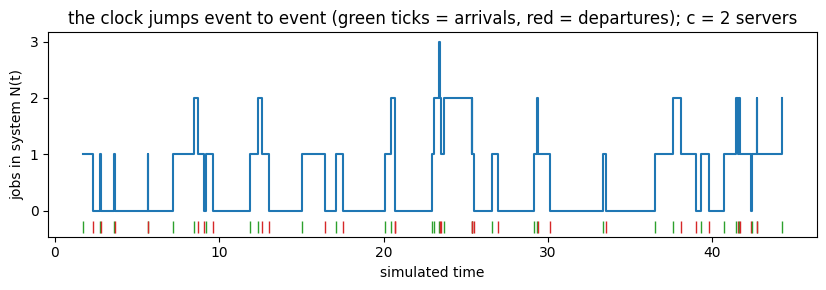

In [2]:
if HAVE_CPU:
    tr = ES.run_cpu(0.9, 1.0, 2, 2_000, warmup=0, seed=4, trace_events=60)["trace"]
    log = pd.DataFrame(tr, columns=["time", "type", "job", "busy servers", "in line"])
    log["type"] = log["type"].map({0: "ARRIVAL", 1: "DEPARTURE"})
    log[["job", "busy servers", "in line"]] = log[["job", "busy servers", "in line"]].astype(int)
    display(log.head(12).round(3))
    N = log["busy servers"] + log["in line"]
    fig, ax = plt.subplots(figsize=(8.5, 3))
    ax.step(log["time"], N, where="post")
    for _, row in log.iterrows():
        ax.plot(row["time"], -0.3, "|", color="C2" if row["type"] == "ARRIVAL" else "C3", ms=8)
    ax.set_xlabel("simulated time"); ax.set_ylabel("jobs in system N(t)")
    ax.set_title("the clock jumps event to event (green ticks = arrivals, red = departures); c = 2 servers")
    plt.tight_layout(); plt.show()

## 2. The exact answers we check against

**M/M/1 (SymPy):** in steady state, the flow from n to n+1 jobs equals the flow back:
λ pₙ = μ pₙ₊₁. So pₙ = (1−ρ)ρⁿ with ρ = λ/μ, and the mean number in the system is the sum
of n·pₙ. **Little's law** L = λW then gives the mean time W without any further work.

In [3]:
lam, mu, rho, n = sp.symbols("lambda mu rho n", positive=True)
p_n = (1 - rho) * rho**n
s = sp.piecewise_fold(sp.summation(n * p_n, (n, 0, sp.oo)))
L_expr = sp.simplify(s.args[0][0] if isinstance(s, sp.Piecewise) else s)   # convergent branch (rho < 1)
print("series converges only for rho < 1: the stability condition lambda < mu")
display(sp.Eq(sp.Symbol("p_n"), p_n), sp.Eq(sp.Symbol("L"), L_expr))
W_expr = sp.simplify((L_expr / lam).subs(rho, lam / mu))
display(sp.Eq(sp.Symbol("W"), W_expr), sp.Eq(sp.Symbol("W_q"), sp.simplify(W_expr - 1 / mu)))

series converges only for rho < 1: the stability condition lambda < mu


**M/M/c (Erlang C):** with offered load a = λ/μ and c servers, the probability that an
arriving job has to wait is

$$C(c,a) = \frac{\dfrac{a^c}{c!}\dfrac{c}{c-a}}{\displaystyle\sum_{k=0}^{c-1}\frac{a^k}{k!} + \frac{a^c}{c!}\frac{c}{c-a}}, \qquad W_q = \frac{C(c,a)}{c\mu - \lambda}.$$

## 3. The C++ event-list simulator vs. the exact answers

In [4]:
cases = [(0.7, 1.0, 1), (2.0, 1.0, 3), (12.0, 4 / 3, 11)]
rows = []
for lam_, mu_, c_ in cases:
    m = QU.mmc_metrics(lam_, mu_, c_)
    if HAVE_CPU:
        r = ES.run_cpu(lam_, mu_, c_, 400_000, warmup=20_000, seed=11)
        sim_wq, sim_pw, sim_L, little = r["mean_wait"], r["p_wait"], r["mean_in_system"], r["arrival_rate"] * r["mean_system"]
    else:
        sim_wq, sim_pw = QU.simulate_mmc(lam_, mu_, c_, 100_000, 5_000, seed=11); sim_L = little = float("nan")
    rows.append((f"lambda={lam_:g}, mu={mu_:.3g}, c={c_}", m["rho"], m["Wq"], sim_wq, m["P_wait"], sim_pw, sim_L, little))
df = pd.DataFrame(rows, columns=["case", "rho", "Wq exact", "Wq sim", "P(wait) exact", "P(wait) sim", "L sim", "lambda*W sim"])
display(df.round(4))
print("Little's law holds inside the simulation: L (time average) = lambda * W (per-job average).")

,case,rho,Wq exact,Wq sim,P(wait) exact,P(wait) sim,L sim,lambda*W sim
0,"lambda=0.7, mu=1, c=1",0.7000,2.3333,2.3894,0.7000,0.7017,2.3753,2.3754
1,"lambda=2, mu=1, c=3",0.6667,0.4444,0.4366,0.4444,0.4401,2.8618,2.8618
2,"lambda=12, mu=1.33, c=11",0.8182,0.1614,0.1689,0.4305,0.4349,11.0368,11.0366


Little's law holds inside the simulation: L (time average) = lambda * W (per-job average).


## 4. CUDA: thousands of replications at once

One long run gives one estimate. Its error bar needs **independent replications**: run the
model many times with different random streams and look at the spread. Each GPU thread runs
one replication. Instead of an event list, which is branchy and serial, the GPU uses the
equivalent Kiefer-Wolfowitz recursion: job i starts at max(arrival, earliest free server).

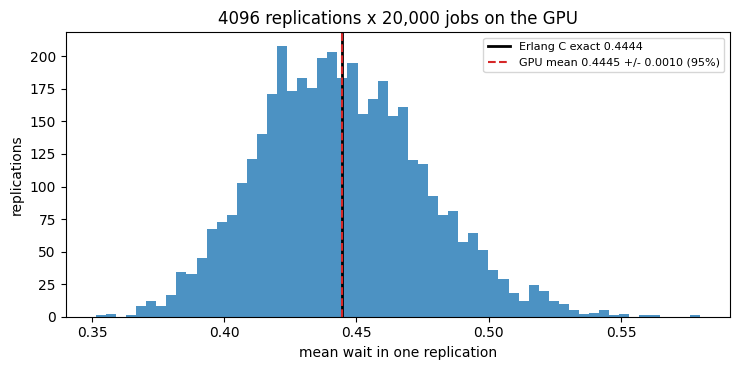

GPU: 90,112,000 simulated jobs, kernel 120 ms (749 M jobs/s), wall incl. process start 0.22 s


CPU event list: 10,240,000 jobs in 0.86 s wall (11.9 M jobs/s, single thread, incl. process start)
exact value inside the 95% interval? True


In [5]:
lam_, mu_, c_ = 2.0, 1.0, 3
exact = QU.mmc_metrics(lam_, mu_, c_)["Wq"]
reps, n_per = 4096, 20_000
if HAVE_GPU:
    g = ES.run_gpu(lam_, mu_, c_, n_per, reps=reps, warmup=2_000, seed=21)
    mean, half = ES.confidence_interval(g["wq"])
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    ax.hist(g["wq"], bins=60, color="C0", alpha=0.8)
    ax.axvline(exact, color="k", lw=2, label=f"Erlang C exact {exact:.4f}")
    ax.axvline(mean, color="C3", ls="--", label=f"GPU mean {mean:.4f} +/- {half:.4f} (95%)")
    ax.set_xlabel("mean wait in one replication"); ax.set_ylabel("replications"); ax.legend(fontsize=8)
    ax.set_title(f"{reps} replications x {n_per:,} jobs on the GPU")
    plt.tight_layout(); plt.show()
    print(f"GPU: {reps * (n_per + 2000):,} simulated jobs, kernel {g['kernel_ms']:.0f} ms "
          f"({reps * (n_per + 2000) / g['kernel_ms'] / 1e3:.0f} M jobs/s), wall incl. process start {g['wall_s']:.2f} s")
    if HAVE_CPU:
        r = ES.run_cpu(lam_, mu_, c_, reps * n_per // 8, warmup=2_000, seed=21)
        print(f"CPU event list: {reps * n_per // 8:,} jobs in {r['wall_s']:.2f} s wall "
              f"({reps * n_per / 8 / r['wall_s'] / 1e6:.1f} M jobs/s, single thread, incl. process start)")
    print("exact value inside the 95% interval?", abs(mean - exact) <= half)
else:
    print("CUDA unavailable: this section needs nvcc and a CUDA GPU.")

## 5. The disaster: how many rescue teams?

*Illustrative:* collapse reports arrive at λ = 12 per hour. A team spends 45 minutes per site
on average, so μ = 4/3 per hour per team and the offered load is a = λ/μ = 9 teams' worth of
work. With 9 teams or fewer, the line grows without bound. The question is how much margin
above 9 is enough.

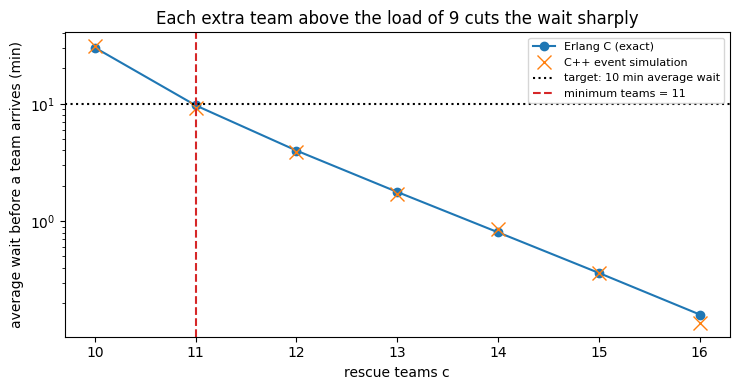

,teams,utilization,P(report waits),Wq exact (min),Wq sim (min)
0,10,0.900,0.669,30.093,30.936
1,11,0.818,0.430,9.686,9.235
2,12,0.750,0.266,3.991,3.892
3,13,0.692,0.158,1.772,1.702
4,14,0.643,0.089,0.803,0.859
5,15,0.600,0.048,0.362,0.361
6,16,0.562,0.025,0.160,0.136


In [6]:
LAM, MU = 12.0, 4 / 3
cs = list(range(10, 17))
ex = [QU.mmc_metrics(LAM, MU, c)["Wq"] * 60 for c in cs]
sim = []
for c in cs:
    if HAVE_CPU:
        sim.append(ES.run_cpu(LAM, MU, c, 200_000, warmup=10_000, seed=100 + c)["mean_wait"] * 60)
    else:
        sim.append(QU.simulate_mmc(LAM, MU, c, 50_000, 5_000, seed=100 + c)[0] * 60)
need = QU.min_servers(LAM, MU, 10 / 60)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.semilogy(cs, ex, "o-", label="Erlang C (exact)")
ax.semilogy(cs, sim, "x", ms=10, label="C++ event simulation" if HAVE_CPU else "NumPy simulation")
ax.axhline(10, color="k", ls=":", label="target: 10 min average wait")
ax.axvline(need, color="C3", ls="--", label=f"minimum teams = {need}")
ax.set_xlabel("rescue teams c"); ax.set_ylabel("average wait before a team arrives (min)")
ax.legend(fontsize=8); ax.set_title("Each extra team above the load of 9 cuts the wait sharply")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"teams": cs, "utilization": [LAM / (c * MU) for c in cs],
                      "P(report waits)": [QU.erlang_c(LAM, MU, c) for c in cs],
                      "Wq exact (min)": ex, "Wq sim (min)": sim}).round(3))

**ENGR 140 tie-in.** Each team costs money per hour, and every report waiting in line has a
cost of delay. Total cost per hour = c·C_team + L_q·C_delay, where L_q = λW_q is the average
number waiting. The cost weights below are illustrative. The shape of the curve is the lesson:
too few teams and the delay cost explodes; too many and you pay for idle teams.

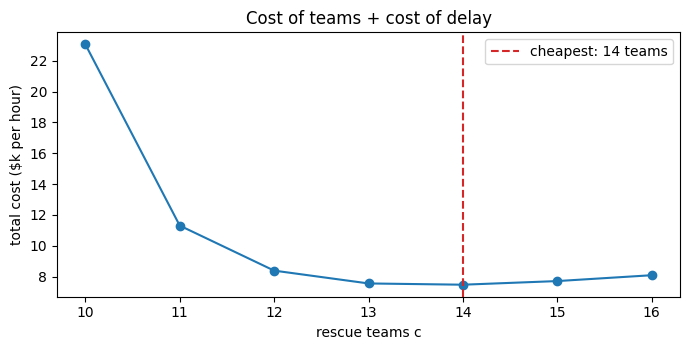

In [7]:
C_TEAM, C_DELAY = 500.0, 3000.0          # $/team-hour and $/(report-hour waiting): illustrative weights
total = [c * C_TEAM + QU.mmc_metrics(LAM, MU, c)["Lq"] * C_DELAY for c in cs]
best = cs[int(np.argmin(total))]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(cs, np.array(total) / 1e3, "o-"); ax.axvline(best, color="C3", ls="--", label=f"cheapest: {best} teams")
ax.set_xlabel("rescue teams c"); ax.set_ylabel("total cost ($k per hour)"); ax.legend()
ax.set_title("Cost of teams + cost of delay")
plt.tight_layout(); plt.show()

## Practice (my own problems)

1. An M/M/1 help desk gets 8 calls/hour and handles 10/hour. Find ρ, L, W, and W_q.
2. For a = 2 Erlangs and c = 3, show C = 4/9 by hand, then compute W_q for μ = 1.
3. In the disaster scenario, what happens to the minimum team count if site work drops to 30 minutes?
4. Why does the GPU kernel not use a priority queue?
5. A run reports L = 14.4 jobs and λ = 12/hour. What is W?

In [8]:
m1 = QU.mmc_metrics(8, 10, 1)
print(f"1. rho = {m1['rho']:.2f}, L = {m1['L']:.2f}, W = {m1['W'] * 60:.1f} min, Wq = {m1['Wq'] * 60:.1f} min")
print(f"2. C = {QU.erlang_c(2, 1, 3):.4f} (4/9 = {4 / 9:.4f}), Wq = {QU.mmc_metrics(2, 1, 3)['Wq']:.4f}")
print(f"3. teams needed: {QU.min_servers(12, 2, 10 / 60)} (was {QU.min_servers(12, 4 / 3, 10 / 60)}); offered load drops from 9 to 6")
print("4. Event lists are branchy and serial; GPU threads run best on identical, branch-light loops,")
print("   so the kernel uses the equivalent recursion, one replication per thread.")
print(f"5. W = L / lambda = {14.4 / 12 * 60:.0f} minutes (Little's law)")

1. rho = 0.80, L = 4.00, W = 30.0 min, Wq = 24.0 min
2. C = 0.4444 (4/9 = 0.4444), Wq = 0.4444
3. teams needed: 8 (was 11); offered load drops from 9 to 6
4. Event lists are branchy and serial; GPU threads run best on identical, branch-light loops,
   so the kernel uses the equivalent recursion, one replication per thread.
5. W = L / lambda = 72 minutes (Little's law)


## Checklist

- [ ] A DES is a future-event list (min-heap on time) plus state. The clock jumps, it doesn't tick.
- [ ] Check a simulator against an exact case before trusting it (Erlang C, Little's law L = λW).
- [ ] Error bars come from independent replications, not from one long run.
- [ ] GPU: one replication per thread, branch-light recursion, independent random streams (Philox).
- [ ] Stability needs λ < cμ. Near ρ → 1, waits explode, so staff above the offered load.
- [ ] gcc builds the C++ event list. nvcc (with MSVC on Windows) builds the CUDA kernel.